# DFT audio analysis 

Take an audio spectrum as input and find out individual frequency involving it using fft

In [1]:
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

In [2]:
# Read audio file
# audio, sample_rate = sf.read("10_frequency_audio.wav")
audio, sample_rate = sf.read("audio.mp3")

In [3]:
# Display basic information
print("Sampling rate:", sample_rate, "Hz")
print("Audio shape:", audio.shape)
print("Duration:", len(audio) / sample_rate, "seconds")

Sampling rate: 24000 Hz
Audio shape: (68544, 2)
Duration: 2.856 seconds


In [4]:
# Convert stereo audio to mono (optional)
if audio.ndim == 2:
    audio = np.mean(audio, axis=1)

## Plot the waveform (time domain)

A waveform represents how the amplitude of an audio signal changes over time.

The horizontal axis represents time, and the vertical axis represents amplitude.

The time corresponding to sample $n$ is:
$$
t_n = \frac{n}{f_s}
$$

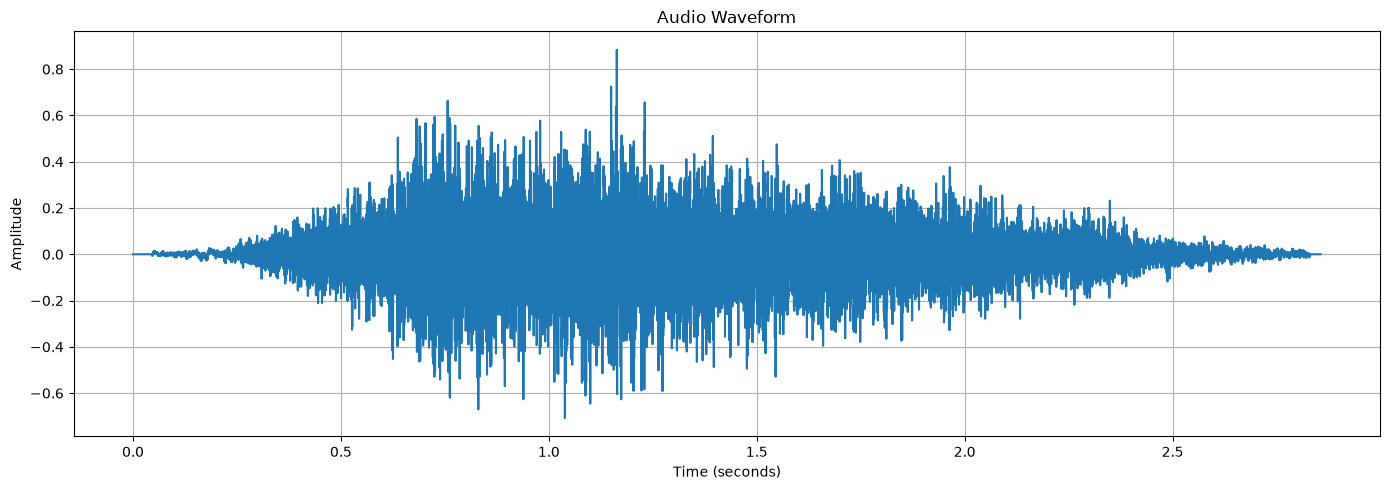

In [5]:
# Generate time values
time = np.arange(len(audio)) / sample_rate

# Plot waveform
plt.figure(figsize=(14, 5))

plt.plot(time, audio)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

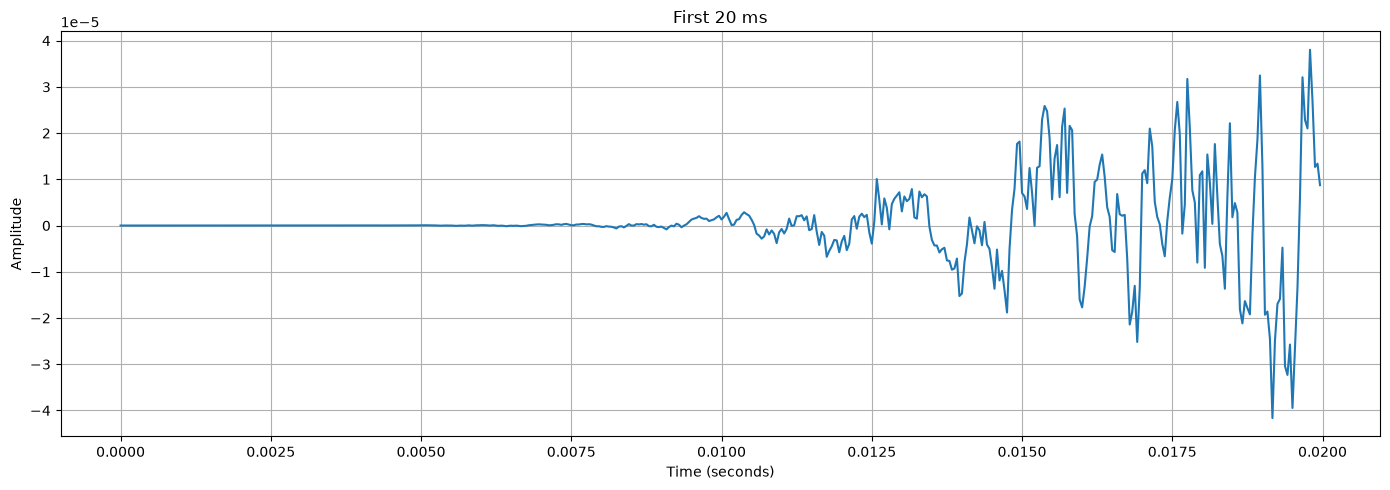

In [6]:
samples = int(0.02 * sample_rate)

plt.figure(figsize=(14, 5))

plt.plot(time[:samples], audio[:samples])

plt.title("First 20 ms")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.tight_layout()
plt.show()

## Perform Fast Fourier Transform (FFT)

The Discrete Fourier Transform (DFT) is:
$$
X[k] =
\sum_{n=0}^{N-1}
x[n]e^{-j2\pi kn/N}
$$

In [7]:
N = len(audio)  # Number of samples

fft_result = np.fft.rfft(audio)

# Calculate corresponding frequency values
frequencies = np.fft.rfftfreq(N, d=1/sample_rate)

# Calculate magnitude
magnitude = np.abs(fft_result)

print("Number of frequency bins:", len(frequencies))

Number of frequency bins: 34273


In [8]:
# Normalize magnitude
magnitude = np.abs(fft_result) / N

# Convert to one-sided amplitude spectrum
if N % 2 == 0:
    magnitude[1:-1] *= 2
else:
    magnitude[1:] *= 2

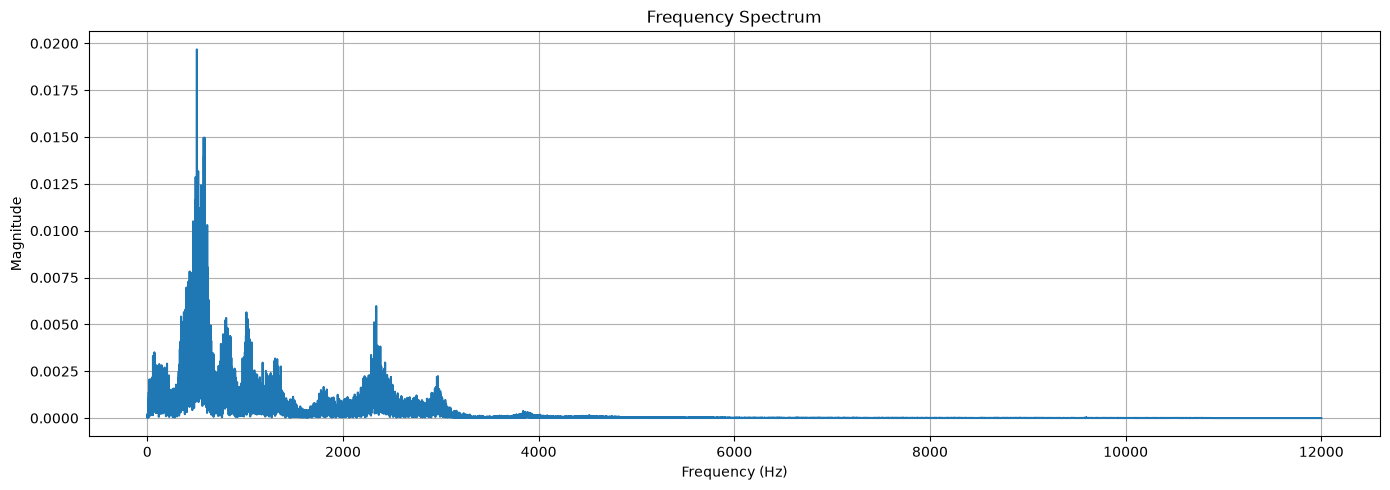

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(frequencies, magnitude)

plt.title("Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)

plt.tight_layout()
plt.show()

### Finding dominant frequency

In [10]:
from scipy.signal import find_peaks

# Find peaks in the magnitude spectrum
peaks, properties = find_peaks(magnitude, prominence=0.001)

# Sort peaks by magnitude
sorted_peaks = peaks[np.argsort(magnitude[peaks])[::-1]]

# Display the 10 strongest peaks
print("Dominant Frequencies:")

for index in sorted_peaks[:10]:
    print(
        f"Frequency: {frequencies[index]:.2f} Hz, "
        f"Magnitude: {magnitude[index]:.6f}"
    )

Dominant Frequencies:
Frequency: 506.65 Hz, Magnitude: 0.019673
Frequency: 585.08 Hz, Magnitude: 0.014964
Frequency: 575.98 Hz, Magnitude: 0.014959
Frequency: 579.13 Hz, Magnitude: 0.013967
Frequency: 519.96 Hz, Magnitude: 0.013177
Frequency: 494.05 Hz, Magnitude: 0.012865
Frequency: 504.20 Hz, Magnitude: 0.012711
Frequency: 514.71 Hz, Magnitude: 0.012669
Frequency: 549.02 Hz, Magnitude: 0.012425
Frequency: 491.25 Hz, Magnitude: 0.011626


## Reconstruction of the waveform

A sinusoidal wave can be represented as:
$$
x(t)=A\sin(2\pi ft+\phi)
$$

For FFT-based reconstruction, cosine is recommended because the complex FFT coefficient naturally gives us its phase in the cosine representation.

The general mathematical expression is:
$$
\boxed{x(t)=A\cos(2\pi ft+\phi)}
$$

Or equivalently:
$$
\boxed{x(t)=A\sin(2\pi ft+\phi+\pi/2)}
$$

In [11]:
# Select the 50 strongest frequency peaks
top_peaks = sorted_peaks[:50]

In [12]:
# Initialize reconstructed signal
reconstructed_wave = np.zeros(N)

# Sample indices
n = np.arange(N)

# Reconstruct using selected peaks
for index in top_peaks:

    # Skip DC and Nyquist (if present)
    if index == 0 or (N % 2 == 0 and index == N // 2):
        continue

    # Calculate amplitude
    amplitude = 2 * np.abs(fft_result[index]) / N

    # Calculate phase
    phase = np.angle(fft_result[index])

    # Calculate frequency component
    reconstructed_wave += amplitude * np.cos(
        2 * np.pi * index * n / N + phase
    )

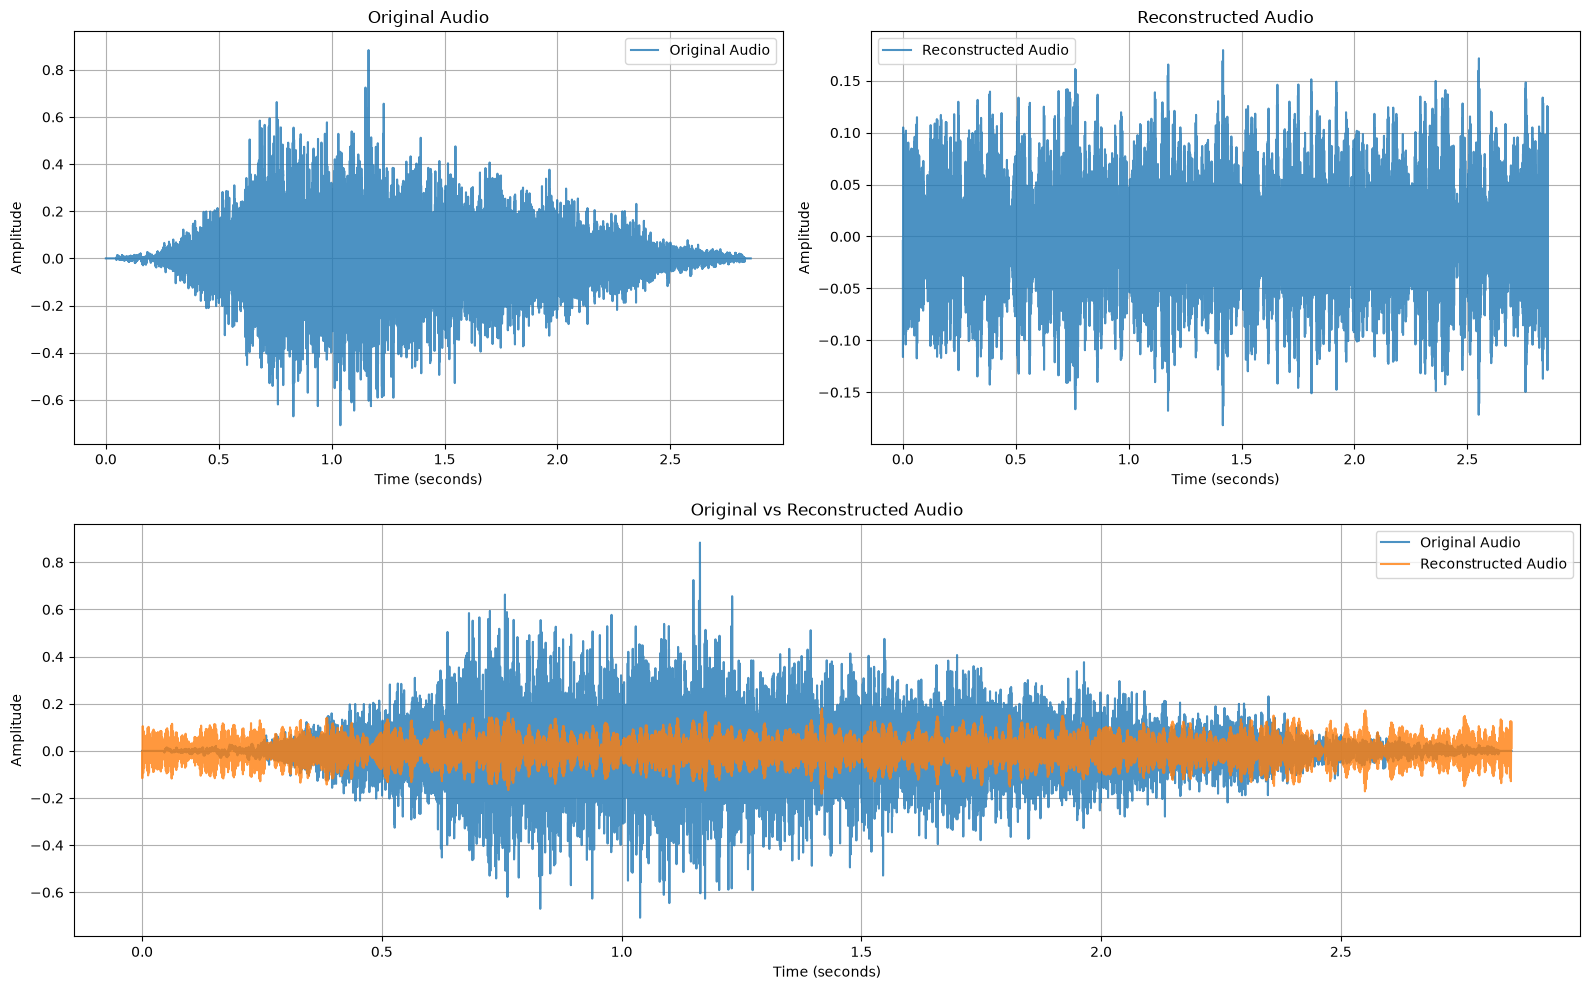

In [13]:
fig = plt.figure(figsize=(16, 10))

gs = fig.add_gridspec(2, 2)

# Plot 1: Original audio
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(time, audio, label="Original Audio", alpha=0.8)

ax1.set_title("Original Audio")
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Amplitude")
ax1.legend()
ax1.grid(True)

# Plot 2: Reconstructed audio
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(time, reconstructed_wave,
         label="Reconstructed Audio", alpha=0.8)

ax2.set_title("Reconstructed Audio")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Amplitude")
ax2.legend()
ax2.grid(True)

# Plot 3: Both signals
ax3 = fig.add_subplot(gs[1, :])

ax3.plot(time, audio,
         label="Original Audio", alpha=0.8)

ax3.plot(time, reconstructed_wave,
         label="Reconstructed Audio", alpha=0.8)

ax3.set_title("Original vs Reconstructed Audio")
ax3.set_xlabel("Time (seconds)")
ax3.set_ylabel("Amplitude")
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

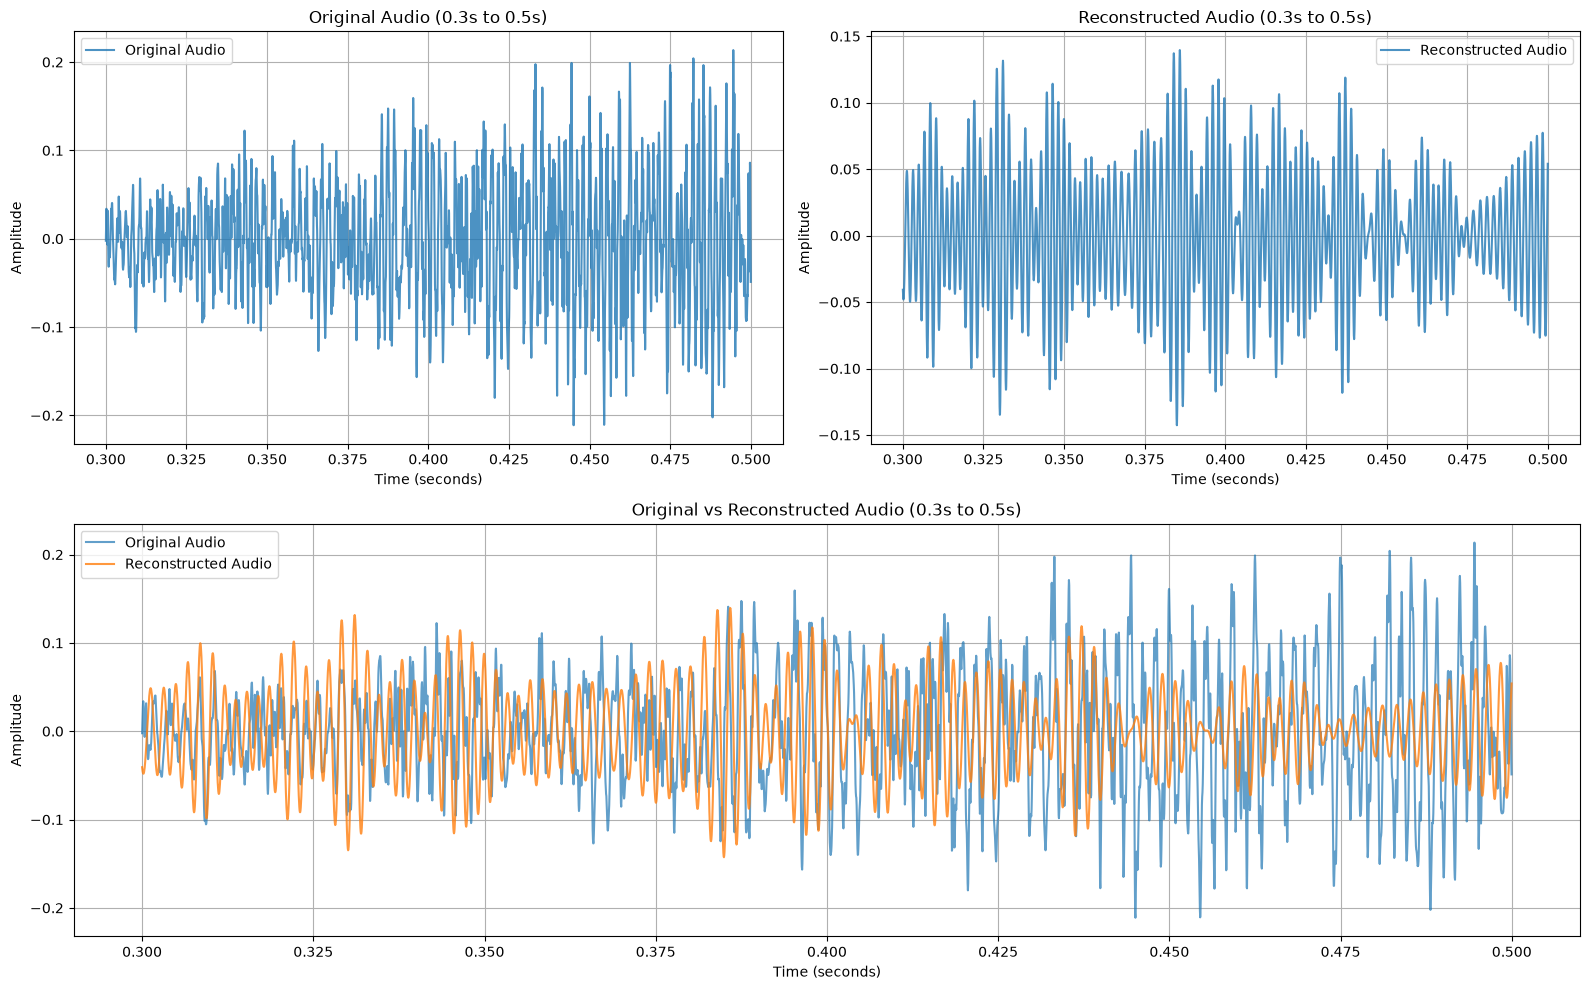

In [14]:
start = int(0.3 * sample_rate)
end = int(0.5 * sample_rate)

fig = plt.figure(figsize=(16, 10))

gs = fig.add_gridspec(2, 2)

# Plot 1: Original audio
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(time[start:end], audio[start:end], label="Original Audio", alpha=0.8)

ax1.set_title("Original Audio (0.3s to 0.5s)")
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Amplitude")
ax1.legend()
ax1.grid(True)

# Plot 2: Reconstructed audio
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(time[start:end], reconstructed_wave[start:end],
         label="Reconstructed Audio", alpha=0.8)

ax2.set_title("Reconstructed Audio (0.3s to 0.5s)")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Amplitude")
ax2.legend()
ax2.grid(True)

# Plot 3: Both signals (first 20 ms)
ax3 = fig.add_subplot(gs[1, :])

ax3.plot(time[start:end], audio[start:end],
         label="Original Audio", alpha=0.7)

ax3.plot(time[start:end], reconstructed_wave[start:end],
         label="Reconstructed Audio", alpha=0.8)

ax3.set_title("Original vs Reconstructed Audio (0.3s to 0.5s)")
ax3.set_xlabel("Time (seconds)")
ax3.set_ylabel("Amplitude")
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

## Creating audio signal

Let's first create a synthetic audio signal with 10 different frequencies and validate above workflow.

Create a 5-second audio file with the following 10 frequencies mixed together.

Frequency components 

100 Hz,	200 Hz, 300 Hz, 440 Hz, 500 Hz, 700 Hz, 1000 Hz, 1500 Hz, 2000 Hz and 3000 Hz

In [15]:
import numpy as np
import soundfile as sf

sample_rate = 44100
duration = 5.0
t = np.arange(int(sample_rate * duration)) / sample_rate

frequencies = [100, 200, 300, 440, 500, 700, 1000, 1500, 2000, 3000]
amplitudes = [0.20, 0.15, 0.12, 0.18, 0.10, 0.14, 0.12, 0.10, 0.08, 0.06]

audio = np.zeros_like(t)

for f, a in zip(frequencies, amplitudes*10):
    audio += a * np.sin(2 * np.pi * f * t)

# Normalize to avoid clipping
audio /= np.max(np.abs(audio))

sf.write("10_frequency_audio.wav", audio, sample_rate)

print("Created audio file")
print(f"Sample rate: {sample_rate} Hz")
print(f"Duration: {duration} seconds")
print(f"Number of frequencies: {len(frequencies)}")
print("Frequencies:", frequencies)

Created audio file
Sample rate: 44100 Hz
Duration: 5.0 seconds
Number of frequencies: 10
Frequencies: [100, 200, 300, 440, 500, 700, 1000, 1500, 2000, 3000]
